### Лабораторна робота №2. Логістична регресія

In [1]:
import pandas as pd

In [2]:
# 1. Відкрити та зчитати файл з даними.
file_path = "Input_Lab-2_3_4_WQ-R.csv"
data = pd.read_csv(file_path, delimiter=";")

In [3]:
# 2. Визначити та вивести кількість записів, а також кількість полів та їх тип у завантаженому наборі даних.
num_records = len(data)
num_fields = len(data.columns)
field_types = data.dtypes

print(f"Кількість записів: {num_records}")
print(f"Кількість полів: {num_fields}")
print("Типи полів:")
print(field_types)

Кількість записів: 1599
Кількість полів: 12
Типи полів:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object


In [4]:
# 3. Вивести перші 10 записів набору даних.
print("\nТипи полів кожного запису:")
print(data.head(10))


Типи полів кожного запису:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   
5            7.4              0.66         0.00             1.8      0.075   
6            7.9              0.60         0.06             1.6      0.069   
7            7.3              0.65         0.00             1.2      0.065   
8            7.8              0.58         0.02             2.0      0.073   
9            7.5              0.50         0.36             6.1      0.071   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                 

In [5]:
# 4. Додати до набору даних атрибут HighQuality, який дорівнює 1, якщо quality більше або дорівнює шести, та 0 в інших випадках.
data['HighQuality'] = data['quality'].apply(lambda x: 1 if x >= 6 else 0)

In [6]:
# 5. Вивести перші 10 записів набору даних та видалити після цього атрибут quality з набору даних.
print("Перші 10 записів після додавання атрибуту HighQuality:")
print(data.head(10))

# Видалення атрибуту quality
data = data.drop('quality', axis=1)

Перші 10 записів після додавання атрибуту HighQuality:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   
5            7.4              0.66         0.00             1.8      0.075   
6            7.9              0.60         0.06             1.6      0.069   
7            7.3              0.65         0.00             1.2      0.065   
8            7.8              0.58         0.02             2.0      0.073   
9            7.5              0.50         0.36             6.1      0.071   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0           

In [7]:
# 6. Перемішати набір даних та розділити його на навчальну (тренувальну) та тестову вибірки, використовуючи функцію ShuffleSplit.
from sklearn.model_selection import ShuffleSplit

# Визначення вхідних ознак (X) та цільової змінної (y) тренувальних та тестових вибірок
def get_train_and_test_sets(data):
    # the dataset is broken into two parts in a ratio of 75:25
    shuffle_split = ShuffleSplit(n_splits=1, test_size=0.25, random_state=16)
    train_index, test_index = next(shuffle_split.split(data))

    train_data = data.iloc[train_index]
    test_data = data.iloc[test_index]
    
    X_train = train_data.drop('HighQuality', axis=1)
    y_train = train_data['HighQuality']

    X_test = test_data.drop('HighQuality', axis=1)
    y_test = test_data['HighQuality']

    return X_train, y_train, X_test, y_test

In [8]:
# 7. Використовуючи відповідні функції бібліотеки scikit-learn, збудувати класифікаційну модель логістичної регресії та навчити її на тренувальній вибірці, 
# вважаючи, що цільова характеристика визначається стовпчиком HighQuality, а всі інші виступають в ролі вихідних аргументів.

from sklearn.linear_model import LogisticRegression

def generate_logreg_model(X_train, y_train, iterations=1000):
    # Ініціалізація та навчання моделі логістичної регресії
    logistic_regression_model = LogisticRegression(random_state=16, max_iter=iterations) #, solver='liblinear')
    return logistic_regression_model.fit(X_train, y_train)

X_train, y_train, X_test, y_test = get_train_and_test_sets(data)
logistic_regression_model = generate_logreg_model(X_train, y_train, iterations=1000)

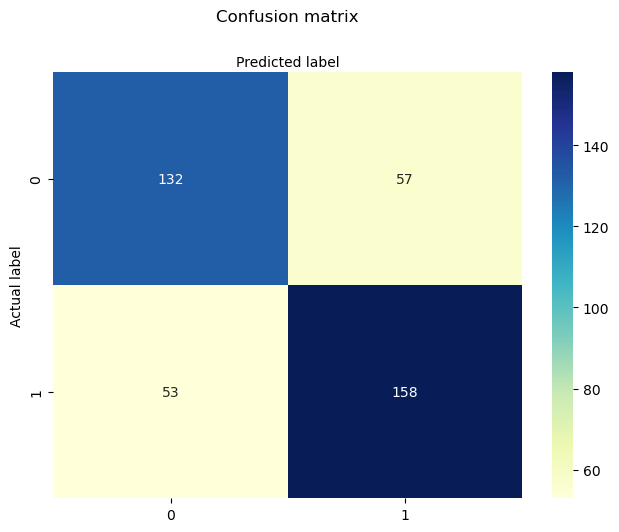

                   precision    recall  f1-score   support

 low quality wine       0.71      0.70      0.71       189
high quality wine       0.73      0.75      0.74       211

         accuracy                           0.73       400
        macro avg       0.72      0.72      0.72       400
     weighted avg       0.72      0.72      0.72       400



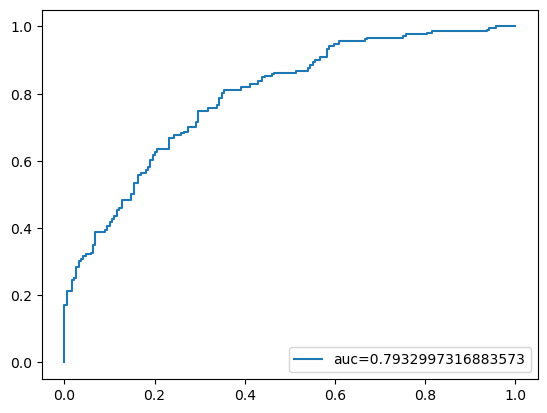

In [9]:
# 8. Обчислити класифікаційні метрики збудованої моделі для тренувальної та тестової вибірки. Представити результати роботи моделі на тестовій вибірці графічно.

# Генерація кривої похибок
def generate_roc(model, X_test, y_test):
    from sklearn import metrics
    y_pred_proba = model.predict_proba(X_test)[::,1]
    fpr, tpr, _ = metrics.roc_curve(y_test,  y_pred_proba)
    auc = metrics.roc_auc_score(y_test, y_pred_proba)
    return fpr, tpr, auc

def estimate_model_performance(model, X_test, y_test):
    from sklearn import metrics
    y_pred = model.predict(X_test)

    # Побудуємо матрицю невідповідностей, де значення по діагоналі представляють к-сть правильних прогнозів, тоді як недіагональні елементи відображають к-сть неправильних
    cnf_matrix = metrics.confusion_matrix(y_test, y_pred)

    # Побудуємо heatmap матриці невідповідностей
    import numpy as np
    import matplotlib.pyplot as plt
    import seaborn as sns
    
    class_names=[0,1] # name  of classes
    fig, ax = plt.subplots()
    tick_marks = np.arange(len(class_names))
    plt.xticks(tick_marks, class_names)
    plt.yticks(tick_marks, class_names)
    # create heatmap
    sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, cmap="YlGnBu" ,fmt='g')
    ax.xaxis.set_label_position("top")
    plt.tight_layout()
    plt.title('Confusion matrix', y=1.1)
    plt.ylabel('Actual label')
    plt.xlabel('Predicted label')
    plt.show()

    # Використання classification_report
    from sklearn.metrics import classification_report
    target_names = ['low quality wine', 'high quality wine']
    print(classification_report(y_test, y_pred, target_names=target_names))
    
    # Побудуємо криву похибок
    fpr, tpr, auc = generate_roc(model, X_test, y_test)
    plt.plot(fpr,tpr,label="auc="+str(auc))
    plt.legend(loc=4)
    plt.show()

estimate_model_performance(logistic_regression_model, X_test, y_test)

/opt/conda/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/opt/conda/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

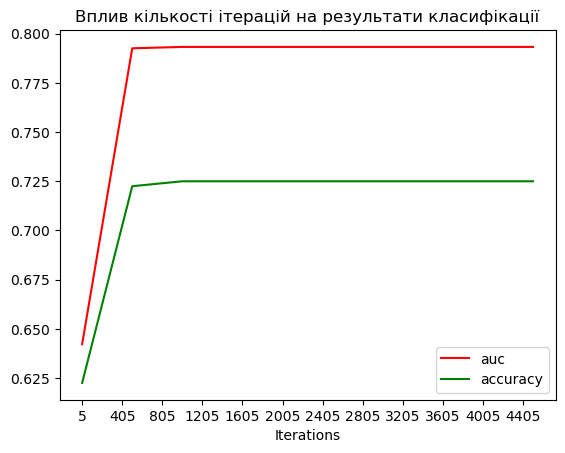

In [10]:
# 9. З’ясувати вплив максимальної кількості ітерацій (від 5 до 5000) на результати класифікації. Результати представити графічно.

import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
import numpy as np

auc_scores = []
accuracy_scores = []
iterations = range(5, 5000, 500)
for i in iterations:
    model = generate_logreg_model(X_train, y_train, i)
    y_pred = model.predict(X_test)
    accuracy_scores.append(accuracy_score(y_test, y_pred))
    
    _, _, auc = generate_roc(model, X_test, y_test)
    auc_scores.append(auc)


# Plotting both the curves simultaneously
plt.plot(iterations, auc_scores, color='r', label='auc')
plt.plot(iterations, accuracy_scores, color='g', label='accuracy')

# Naming the x-axis, y-axis and the whole graph
plt.xlabel("Iterations")
plt.title("Bплив кількості ітерацій на результати класифікації")

# Adding legend, which helps us recognize the curve according to its color 
plt.legend()
plt.xticks(np.arange(min(iterations), max(iterations)+1, 400.0))

plt.show()

In [11]:
# 10. Проаналізувати ступінь впливу атрибутів на результат класифікації. Збудувати класифікаційну модель логістичної регресії,
# залишивши від 3 до 5 найбільш важливих атрибутів та порівняти її результати із моделлю з п. 7.

number_of_important_features = 4

# https://stackoverflow.com/questions/34052115/how-to-find-the-importance-of-the-features-for-a-logistic-regression-model

# 1st approach
print((np.std(data.drop('HighQuality', axis=1), 0)*logistic_regression_model.coef_[0]).sort_values())

from sklearn.inspection import permutation_importance

# 2nd approach
features_names = data.drop('HighQuality', axis=1).columns
importances_mean = permutation_importance(logistic_regression_model, data.drop('HighQuality', axis=1), data['HighQuality'])['importances_mean']
features_importances = dict(zip(features_names, importances_mean))

def find_top_n_keys(dictionary, n):
    # Sort the dictionary based on values in descending order
    sorted_dict = sorted(dictionary.items(), key=lambda x: x[1], reverse=True)
    
    # Extract the keys of the top n entries
    top_n_keys = [key for key, _ in sorted_dict[:n]]
    
    return top_n_keys

important_features_names = find_top_n_keys(features_importances, number_of_important_features)
data_relevant = data[important_features_names + ['HighQuality']]
data_relevant

volatile acidity       -0.511101
total sulfur dioxide   -0.471354
citric acid            -0.194781
chlorides              -0.066772
pH                     -0.061159
density                -0.000155
residual sugar          0.063898
free sulfur dioxide     0.103730
fixed acidity           0.150834
sulphates               0.324441
alcohol                 1.056042
dtype: float64


,alcohol,volatile acidity,total sulfur dioxide,sulphates,HighQuality
0,9.4,0.700,34.0,0.56,0
1,9.8,0.880,67.0,0.68,0
2,9.8,0.760,54.0,0.65,0
3,9.8,0.280,60.0,0.58,1
4,9.4,0.700,34.0,0.56,0
...,...,...,...,...,...
1594,10.5,0.600,44.0,0.58,0
1595,11.2,0.550,51.0,0.76,1
1596,11.0,0.510,40.0,0.75,1
1597,10.2,0.645,44.0,0.71,0


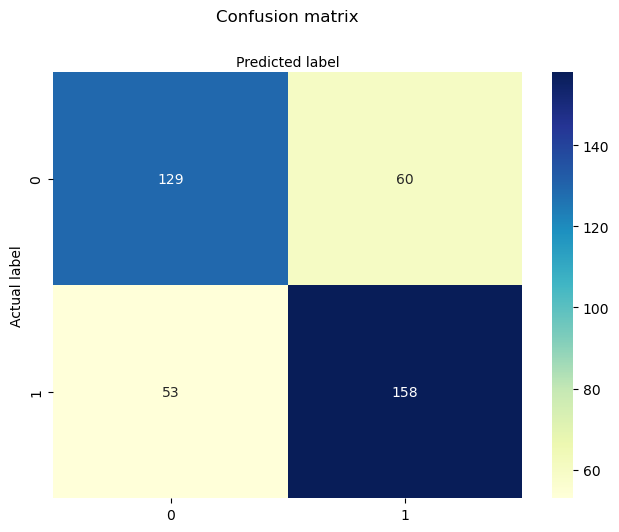

                   precision    recall  f1-score   support

 low quality wine       0.71      0.68      0.70       189
high quality wine       0.72      0.75      0.74       211

         accuracy                           0.72       400
        macro avg       0.72      0.72      0.72       400
     weighted avg       0.72      0.72      0.72       400



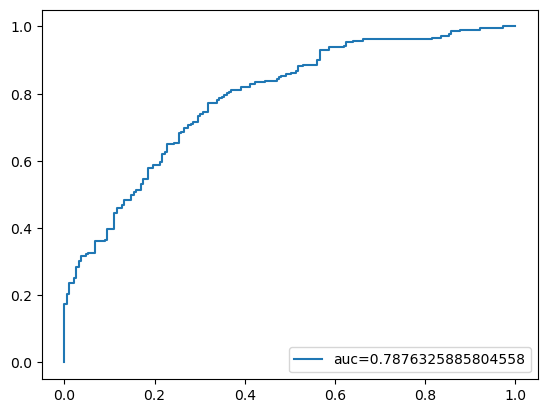

In [12]:
X_train_relevant, y_train_relevant, X_test_relevant, y_test_relevant = get_train_and_test_sets(data_relevant)

logistic_regression_model_relevant = generate_logreg_model(X_train_relevant, y_train_relevant, iterations=1000)
estimate_model_performance(logistic_regression_model_relevant, X_test_relevant, y_test_relevant)